# Ad Campaign Engagement Prediction Model

### Project Overview & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

### Data Loading & Inspection

In [2]:
df = pd.read_csv("ad_engagement_prediction_dataset.csv")
df

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Device Type,Browser,Clicks,Ad Category,Session Duration,Previous Purchases,Clicked on Ad
0,52.472407,39,65022.610586,163.828372,0,Tablet,Edge,1,Tech,36.112463,4,0
1,87.042858,19,45717.608058,203.969724,1,Tablet,Chrome,1,Finance,43.629409,3,1
2,73.919637,21,21247.594223,115.983857,0,Tablet,Firefox,8,Finance,7.902436,4,0
3,65.919509,62,25281.958921,197.042706,0,Tablet,Safari,8,Finance,18.914901,2,1
4,39.361118,30,49335.837262,284.914781,1,Mobile,Edge,9,Tech,23.779108,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
19995,82.622318,20,44901.120291,173.116340,0,Desktop,Firefox,8,Health,24.722930,2,1
19996,32.808837,25,57953.730387,166.516618,0,Mobile,Firefox,5,Fashion,43.959437,2,0
19997,48.221908,34,20881.388580,153.792947,1,Desktop,Safari,7,Tech,10.610399,4,0
19998,56.599200,21,42353.399938,176.055271,1,Mobile,Edge,9,Finance,47.109276,2,0


In [3]:
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Device Type,Browser,Clicks,Ad Category,Session Duration,Previous Purchases,Clicked on Ad
0,52.472407,39,65022.610586,163.828372,0,Tablet,Edge,1,Tech,36.112463,4,0
1,87.042858,19,45717.608058,203.969724,1,Tablet,Chrome,1,Finance,43.629409,3,1
2,73.919637,21,21247.594223,115.983857,0,Tablet,Firefox,8,Finance,7.902436,4,0
3,65.919509,62,25281.958921,197.042706,0,Tablet,Safari,8,Finance,18.914901,2,1
4,39.361118,30,49335.837262,284.914781,1,Mobile,Edge,9,Tech,23.779108,1,0


In [4]:
df.tail()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Device Type,Browser,Clicks,Ad Category,Session Duration,Previous Purchases,Clicked on Ad
19995,82.622318,20,44901.120291,173.116340,0,Desktop,Firefox,8,Health,24.722930,2,1
19996,32.808837,25,57953.730387,166.516618,0,Mobile,Firefox,5,Fashion,43.959437,2,0
19997,48.221908,34,20881.388580,153.792947,1,Desktop,Safari,7,Tech,10.610399,4,0
19998,56.599200,21,42353.399938,176.055271,1,Mobile,Edge,9,Finance,47.109276,2,0
19999,40.335889,38,20713.679895,201.057674,1,Mobile,Edge,2,Finance,32.255124,4,0


In [5]:
df.shape

(20000, 12)

In [6]:
df.columns

Index(['Daily Time Spent on Site', 'Age', 'Area Income',
       'Daily Internet Usage', 'Male', 'Device Type', 'Browser', 'Clicks',
       'Ad Category', 'Session Duration', 'Previous Purchases',
       'Clicked on Ad'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  20000 non-null  float64
 1   Age                       20000 non-null  int64  
 2   Area Income               20000 non-null  float64
 3   Daily Internet Usage      20000 non-null  float64
 4   Male                      20000 non-null  int64  
 5   Device Type               20000 non-null  object 
 6   Browser                   20000 non-null  object 
 7   Clicks                    20000 non-null  int64  
 8   Ad Category               20000 non-null  object 
 9   Session Duration          20000 non-null  float64
 10  Previous Purchases        20000 non-null  int64  
 11  Clicked on Ad             20000 non-null  int64  
dtypes: float64(4), int64(5), object(3)
memory usage: 1.8+ MB


In [8]:
df.describe()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicks,Session Duration,Previous Purchases,Clicked on Ad
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,59.960683,41.041850,44910.151131,200.353354,0.501200,4.976300,32.450192,2.001750,0.510050
std,17.310176,13.537956,14445.191927,57.488176,0.500011,2.585763,15.862394,1.416103,0.499911
min,30.000698,18.000000,20000.276834,100.001686,0.000000,1.000000,5.000125,0.000000,0.000000
25%,44.993206,29.000000,32382.296454,151.102684,0.000000,3.000000,18.770624,1.000000,0.000000
50%,59.935908,41.000000,44910.105982,200.371679,1.000000,5.000000,32.291813,2.000000,1.000000
75%,74.948459,53.000000,57424.885032,250.567807,1.000000,7.000000,46.247550,3.000000,1.000000
max,89.995490,64.000000,69998.607368,299.987939,1.000000,9.000000,59.993711,4.000000,1.000000


### Data cleaning & Quality Checks

In [9]:
df.isnull().sum()

Daily Time Spent on Site    0
Age                         0
Area Income                 0
Daily Internet Usage        0
Male                        0
Device Type                 0
Browser                     0
Clicks                      0
Ad Category                 0
Session Duration            0
Previous Purchases          0
Clicked on Ad               0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

## Exploratory Data Analysis (EDA)

In [11]:
df["Clicked on Ad"].value_counts()

Clicked on Ad
1    10201
0     9799
Name: count, dtype: int64

In [12]:
df["Clicked on Ad"].value_counts(normalize=True) * 100

Clicked on Ad
1    51.005
0    48.995
Name: proportion, dtype: float64

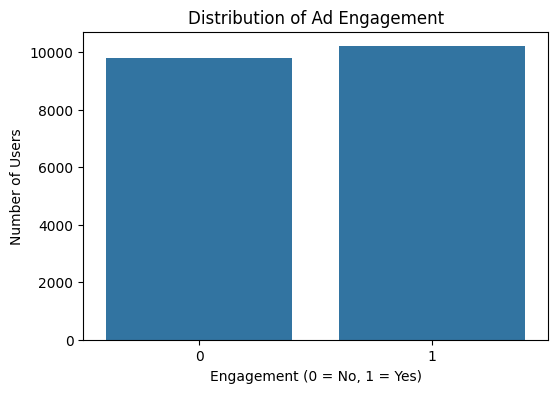

In [13]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Clicked on Ad")

plt.title("Distribution of Ad Engagement")
plt.xlabel("Engagement (0 = No, 1 = Yes)")
plt.ylabel("Number of Users")

plt.show()

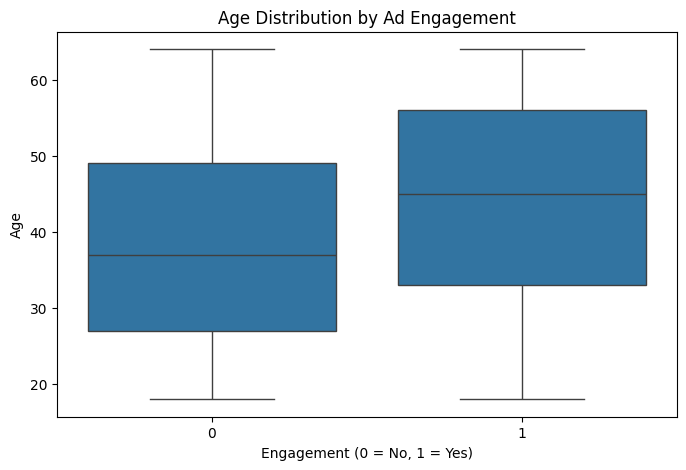

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Clicked on Ad", y="Age")

plt.title("Age Distribution by Ad Engagement")
plt.xlabel("Engagement (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

### AD TYPE ANALAYSIS

In [15]:
platform_engagement = df.groupby("Device Type")["Clicked on Ad"].mean().sort_values(ascending=False)

platform_engagement

Device Type
Mobile     0.513409
Tablet     0.508500
Desktop    0.508204
Name: Clicked on Ad, dtype: float64

In [16]:
platform_engagement * 100

Device Type
Mobile     51.340882
Tablet     50.849985
Desktop    50.820419
Name: Clicked on Ad, dtype: float64

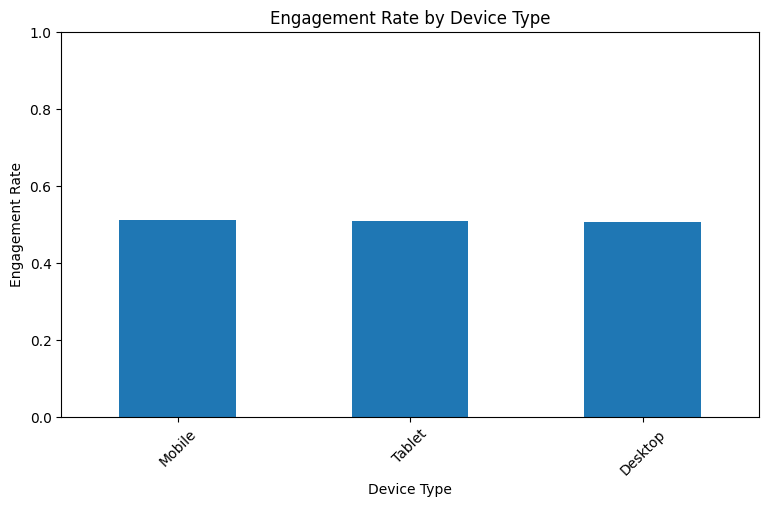

In [17]:
plt.figure(figsize=(9, 5))

platform_engagement = df.groupby("Device Type")["Clicked on Ad"].mean().sort_values(ascending=False)

platform_engagement.plot(kind="bar")

plt.title("Engagement Rate by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()

In [18]:
adtype_engagement = df.groupby("Ad Category")["Clicked on Ad"].mean().sort_values(ascending=False)
adtype_engagement * 100

Ad Category
Fashion    51.700000
Finance    51.400731
Health     50.530452
Tech       50.401284
Name: Clicked on Ad, dtype: float64

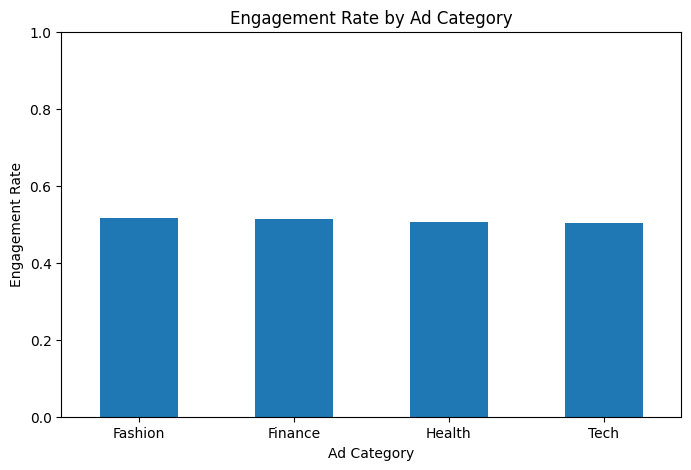

In [19]:
plt.figure(figsize=(8, 5))

adtype_engagement = df.groupby("Ad Category")["Clicked on Ad"].mean().sort_values(ascending=False)

adtype_engagement.plot(kind="bar")

plt.title("Engagement Rate by Ad Category")
plt.xlabel("Ad Category")
plt.ylabel("Engagement Rate")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

In [20]:
interest_engagement = df.groupby("Browser")["Clicked on Ad"].mean().sort_values(ascending=False)
interest_engagement * 100

Browser
Safari     51.533742
Firefox    51.190949
Edge       51.087394
Chrome     50.192191
Name: Clicked on Ad, dtype: float64

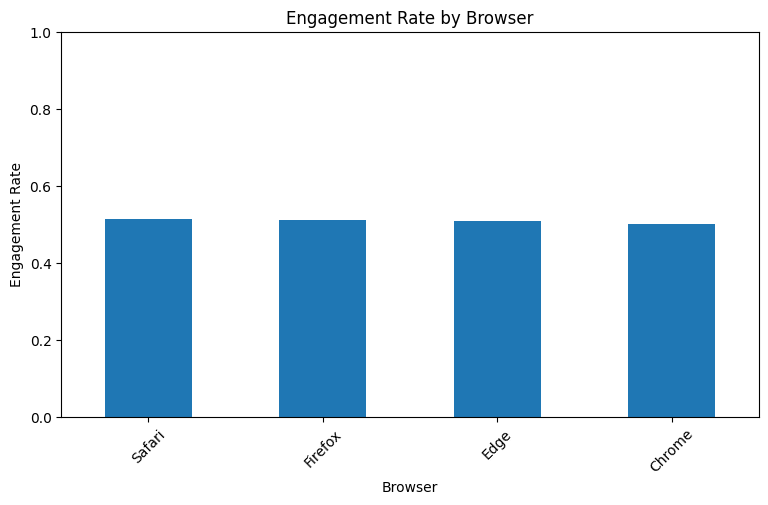

In [21]:
plt.figure(figsize=(9, 5))

interest_engagement = df.groupby("Browser")["Clicked on Ad"].mean().sort_values(ascending=False)

interest_engagement.plot(kind="bar")

plt.title("Engagement Rate by Browser")
plt.xlabel("Browser")
plt.ylabel("Engagement Rate")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()

In [22]:
time_engagement = df.groupby("Previous Purchases")["Clicked on Ad"].mean().sort_values(ascending=False)

time_engagement * 100

Previous Purchases
4    51.883053
0    51.705115
1    51.697646
2    50.163852
3    49.547056
Name: Clicked on Ad, dtype: float64

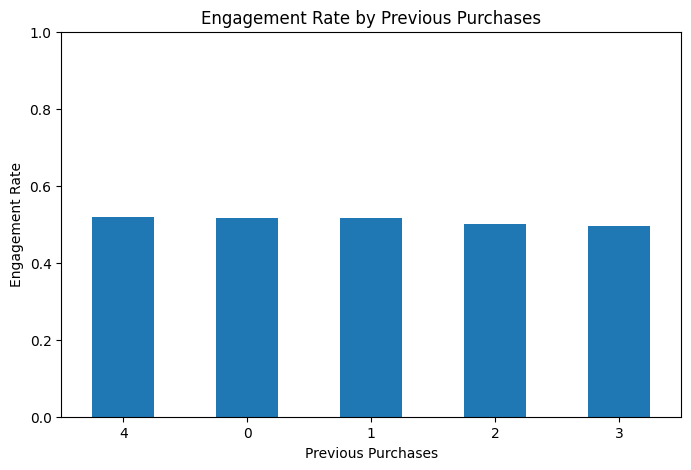

In [23]:
plt.figure(figsize=(8, 5))

time_engagement = df.groupby("Previous Purchases")["Clicked on Ad"].mean().sort_values(ascending=False)

time_engagement.plot(kind="bar")

plt.title("Engagement Rate by Previous Purchases")
plt.xlabel("Previous Purchases")
plt.ylabel("Engagement Rate")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

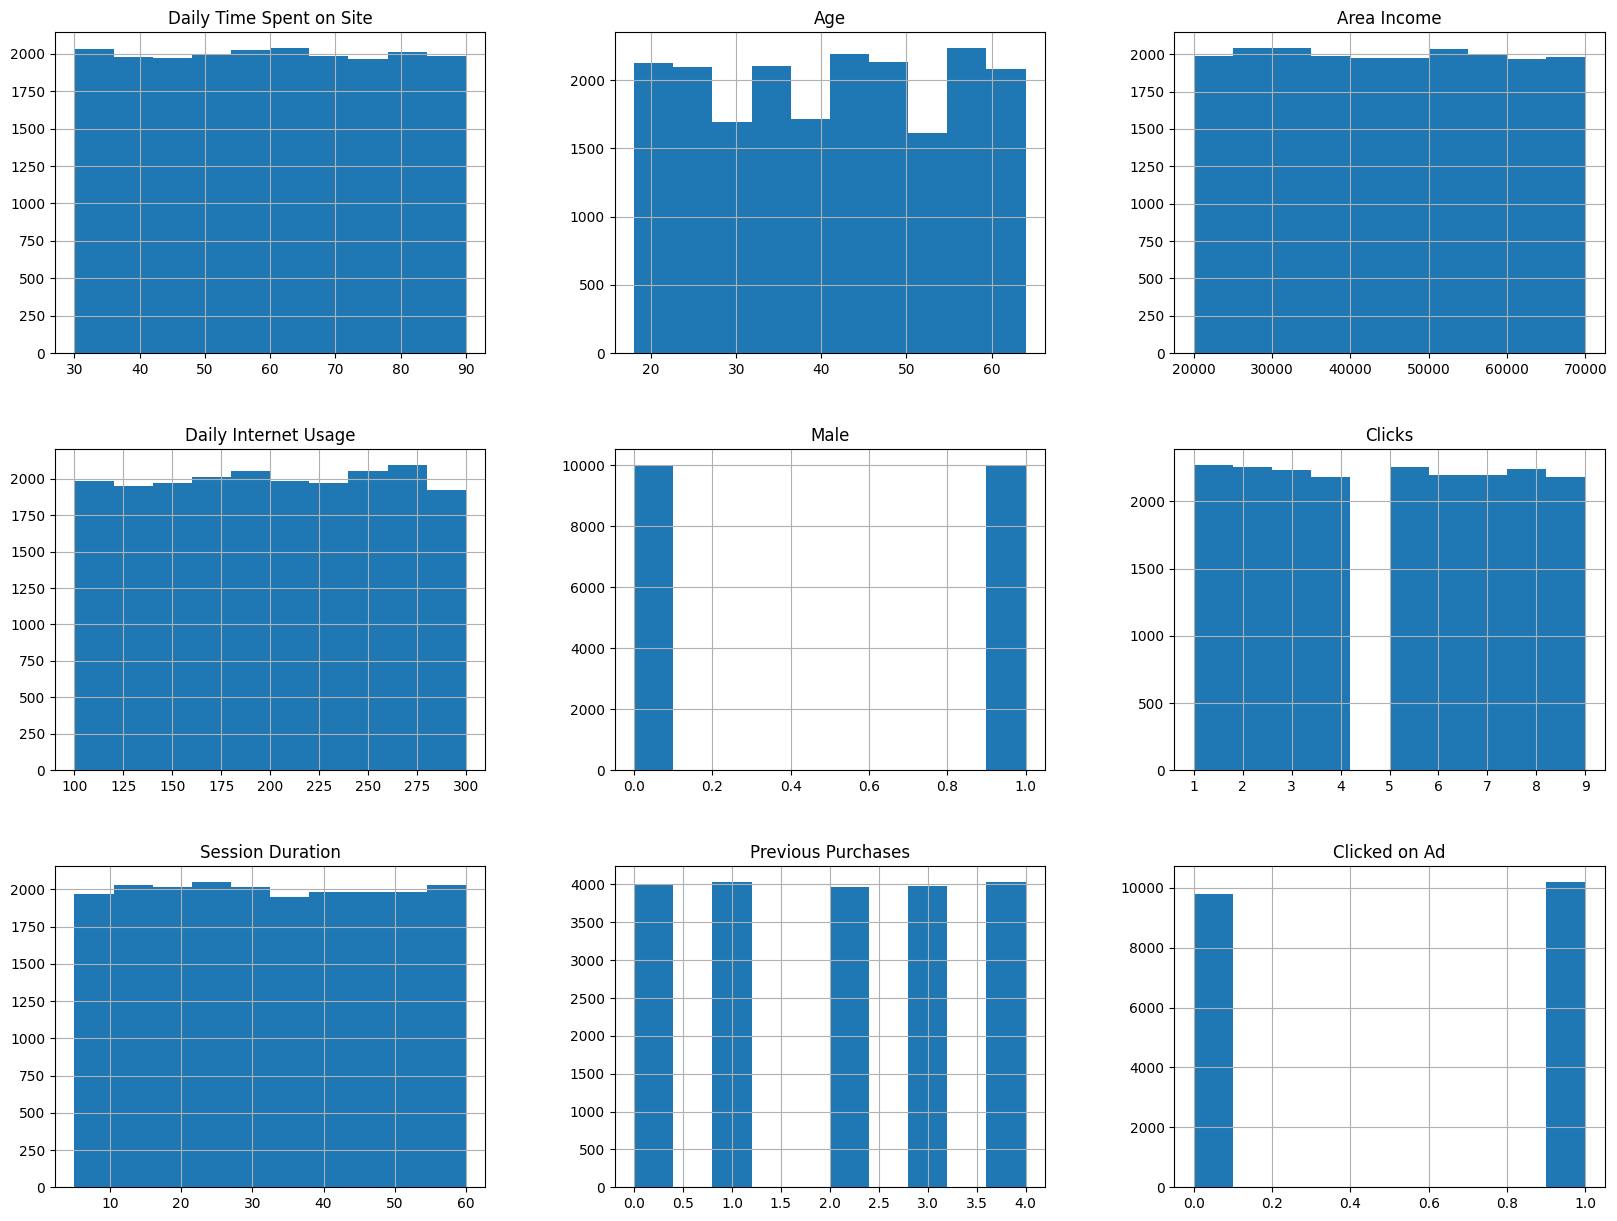

In [24]:
fg = df.select_dtypes(include="number")
fg.hist(figsize=(20,15));
plt.savefig("plt.png")

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'Daily Time Spent on Site'),
  Text(1, 0, 'Age'),
  Text(2, 0, 'Area Income'),
  Text(3, 0, 'Daily Internet Usage'),
  Text(4, 0, 'Male'),
  Text(5, 0, 'Clicks'),
  Text(6, 0, 'Session Duration'),
  Text(7, 0, 'Previous Purchases'),
  Text(8, 0, 'Clicked on Ad')])

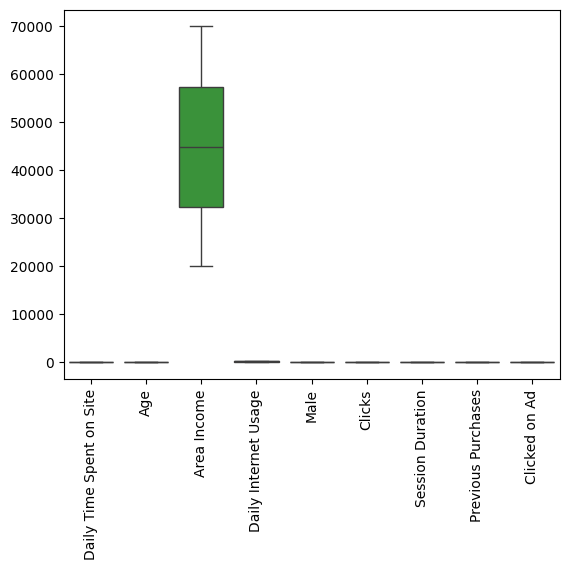

In [25]:
sns.boxplot(df)
plt.xticks(rotation=90)

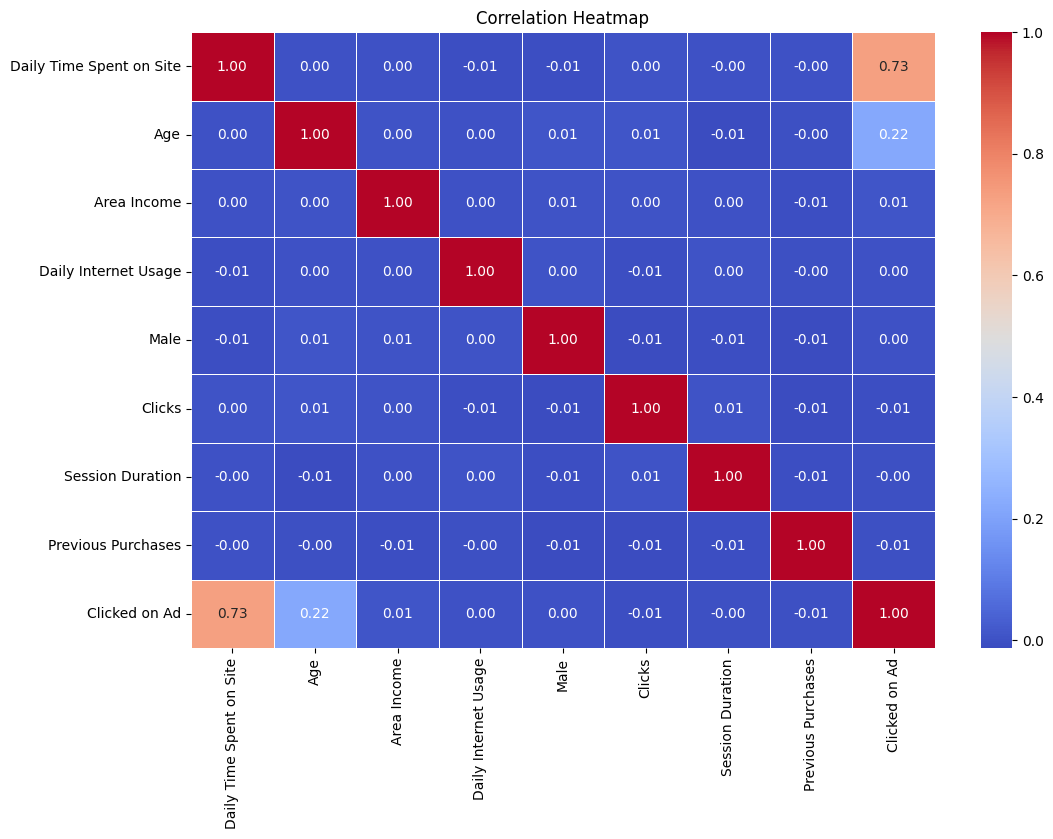

In [26]:
a = df.corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(a, annot=True, fmt=".2f",cmap="coolwarm", linewidths=0.5, cbar=True)
plt.title("Correlation Heatmap")
plt.show()

### Outlier Detection using IQR

In [27]:
numeric_df = df.select_dtypes(include="number")

Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = ((numeric_df < lower_limit) |
            (numeric_df > upper_limit)).sum()

print("Outliers in each numerical column:")
print(outliers)

Outliers in each numerical column:
Daily Time Spent on Site    0
Age                         0
Area Income                 0
Daily Internet Usage        0
Male                        0
Clicks                      0
Session Duration            0
Previous Purchases          0
Clicked on Ad               0
dtype: int64


## Problem Statement & Project Objectives

In [28]:
X = df.drop(columns=["Clicked on Ad"])
y = df["Clicked on Ad"]

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['Daily Time Spent on Site', 'Age', 'Area Income',
       'Daily Internet Usage', 'Male', 'Device Type', 'Browser', 'Clicks',
       'Ad Category', 'Session Duration', 'Previous Purchases'],
      dtype='object')

Target:
Clicked on Ad


In [29]:
print("Categorical Columns:")
print(X.select_dtypes(include="object").columns.tolist())

print("\nNumerical Columns:")
print(X.select_dtypes(include=["int64", "float64"]).columns.tolist())

Categorical Columns:
['Device Type', 'Browser', 'Ad Category']

Numerical Columns:
['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male', 'Clicks', 'Session Duration', 'Previous Purchases']


### Data Preprocessing & Feature Encoding

In [30]:
X_encoded = pd.get_dummies(X, drop_first=True)

X_encoded.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicks,Session Duration,Previous Purchases,Device Type_Mobile,Device Type_Tablet,Browser_Edge,Browser_Firefox,Browser_Safari,Ad Category_Finance,Ad Category_Health,Ad Category_Tech
0,52.472407,39,65022.610586,163.828372,0,1,36.112463,4,False,True,True,False,False,False,False,True
1,87.042858,19,45717.608058,203.969724,1,1,43.629409,3,False,True,False,False,False,True,False,False
2,73.919637,21,21247.594223,115.983857,0,8,7.902436,4,False,True,False,True,False,True,False,False
3,65.919509,62,25281.958921,197.042706,0,8,18.914901,2,False,True,False,False,True,True,False,False
4,39.361118,30,49335.837262,284.914781,1,9,23.779108,1,True,False,True,False,False,False,False,True


### Training and Testing Data Split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16000, 16)
Testing data: (4000, 16)


### Feature Scaling

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Class Balancing Using SMOTE

In [33]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled, y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Clicked on Ad
1    8161
0    7839
Name: count, dtype: int64

After SMOTE:
Clicked on Ad
0    8161
1    8161
Name: count, dtype: int64


## LOGISTIC REGRESSION

In [34]:
logistic_model = LogisticRegression(max_iter=2000)

logistic_model.fit(X_train_smote, y_train_smote)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [35]:
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", logistic_accuracy)
print("Accuracy (%):", logistic_accuracy * 100)

Logistic Regression Accuracy: 0.85125
Accuracy (%): 85.125


In [36]:
print("Classification Report - Logistic Regression")
print(classification_report(y_test, y_pred_logistic))

Classification Report - Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1960
           1       0.86      0.85      0.85      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



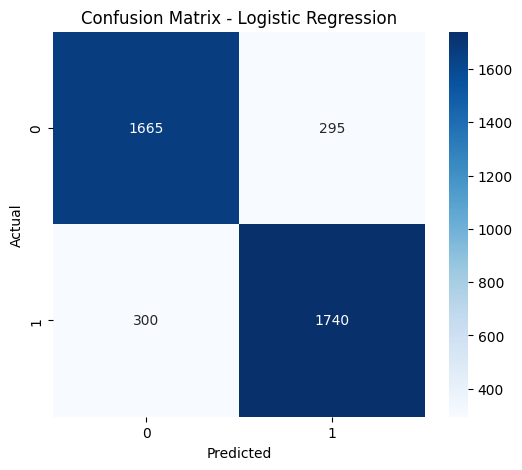

In [37]:
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6,5))
sns.heatmap(cm_logistic, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## DECISION TREE

In [38]:
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree.fit(X_train_scaled, y_train)

y_pred_tree = decision_tree.predict(X_test_scaled)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [39]:
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy)
print("Accuracy (%):", tree_accuracy * 100)

Decision Tree Accuracy: 0.854
Accuracy (%): 85.39999999999999


In [40]:
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1960
           1       0.85      0.86      0.86      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



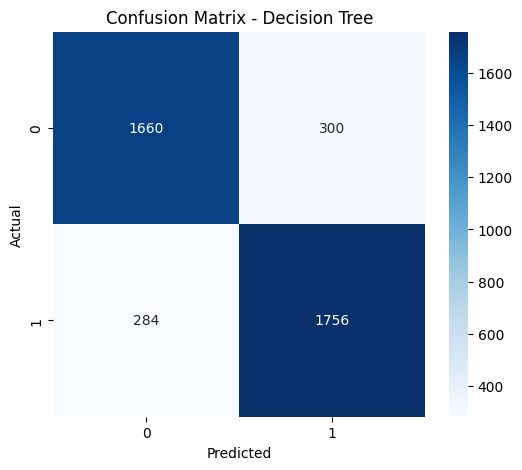

In [41]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(6,5))
sns.heatmap(cm_tree, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## RANDOM FOREST

In [42]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train_scaled, y_train)

y_pred_rf = random_forest.predict(X_test_scaled)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [43]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy (%):", rf_accuracy * 100)

Random Forest Accuracy: 0.84775
Random Forest Accuracy (%): 84.775


In [44]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.85      0.84      0.84      1960
           1       0.85      0.86      0.85      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



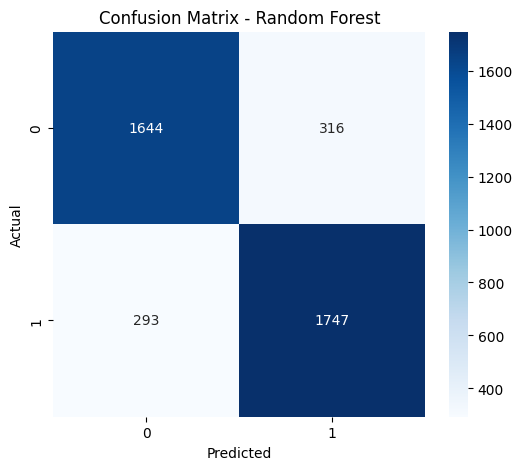

In [45]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## KNN

In [46]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [47]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)
print("Accuracy (%):", knn_accuracy * 100)

KNN Accuracy: 0.8
Accuracy (%): 80.0


In [48]:
print("Classification Report - KNN")
print(classification_report(y_test, y_pred_knn))

Classification Report - KNN
              precision    recall  f1-score   support

           0       0.80      0.79      0.79      1960
           1       0.80      0.81      0.81      2040

    accuracy                           0.80      4000
   macro avg       0.80      0.80      0.80      4000
weighted avg       0.80      0.80      0.80      4000



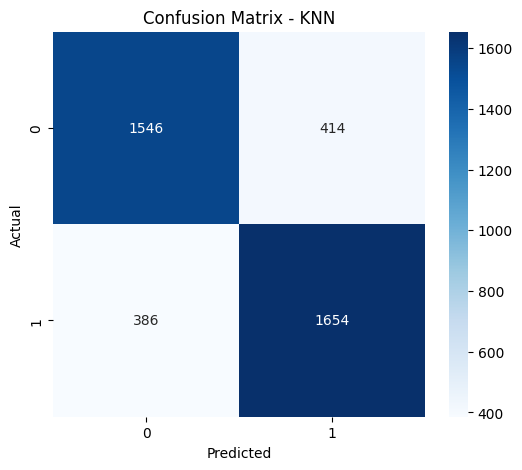

In [49]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6,5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap="Blues")

plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## SVC

In [50]:
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf', random_state=42)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("SVC Model Trained Successfully!")

SVC Model Trained Successfully!


In [51]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)
print("Accuracy (%):", svm_accuracy * 100)

SVM Accuracy: 0.852
Accuracy (%): 85.2


In [52]:
print("Classification Report - SVM")
print(classification_report(y_test, y_pred_svm))

Classification Report - SVM
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1960
           1       0.85      0.86      0.86      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



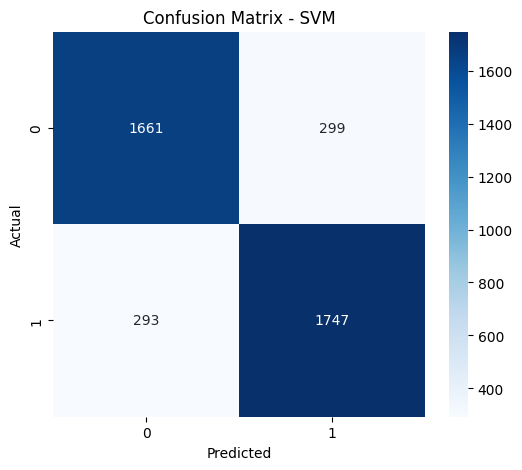

In [53]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6,5))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap="Blues")

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## NAIVE BAYES

In [54]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

nb.fit(X_train_scaled, y_train)

print("Naive Bayes Model Trained Successfully")

Naive Bayes Model Trained Successfully


In [55]:
from sklearn.metrics import accuracy_score

y_pred_nb = nb.predict(X_test_scaled)

nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", nb_accuracy)
print("Accuracy (%):", nb_accuracy * 100)

Naive Bayes Accuracy: 0.84725
Accuracy (%): 84.725


In [56]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

           0       0.85      0.84      0.84      1960
           1       0.85      0.85      0.85      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



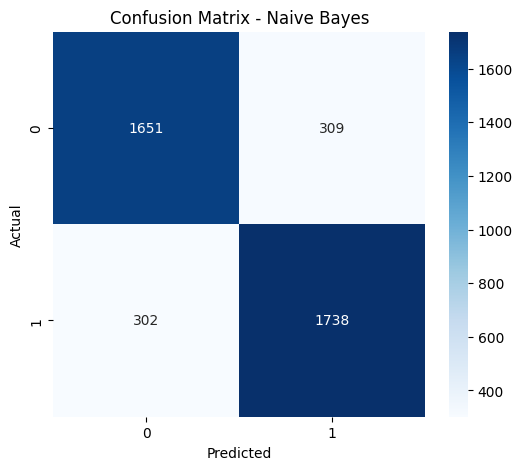

In [57]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6,5))
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## GRADIENT BOOSTING

In [58]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gradient_boosting.fit(X_train_scaled, y_train)

print("Gradient Boosting Model Trained Successfully")

Gradient Boosting Model Trained Successfully


In [59]:
from sklearn.metrics import accuracy_score

y_pred_gb = gradient_boosting.predict(X_test_scaled)

gb_accuracy = accuracy_score(y_test, y_pred_gb)

print("Gradient Boosting Accuracy:", gb_accuracy)
print("Accuracy (%):", gb_accuracy * 100)

Gradient Boosting Accuracy: 0.85275
Accuracy (%): 85.275


In [60]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1960
           1       0.85      0.86      0.86      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



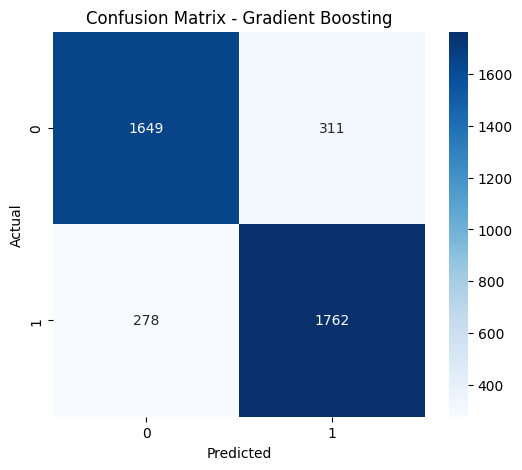

In [61]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_gb = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(6,5))
sns.heatmap(cm_gb, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## ADA BOOST

In [62]:
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

adaboost.fit(X_train_scaled, y_train)

print("AdaBoost Model Trained Successfully")

AdaBoost Model Trained Successfully


In [63]:
from sklearn.metrics import accuracy_score

y_pred_ada = adaboost.predict(X_test_scaled)

ada_accuracy = accuracy_score(y_test, y_pred_ada)

print("AdaBoost Accuracy:", ada_accuracy)
print("Accuracy (%):", ada_accuracy * 100)

AdaBoost Accuracy: 0.85325
Accuracy (%): 85.32499999999999


In [64]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_ada))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1960
           1       0.86      0.85      0.85      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



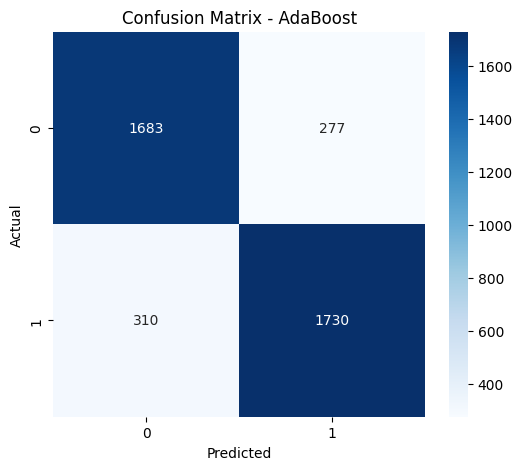

In [65]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_ada = confusion_matrix(y_test, y_pred_ada)

plt.figure(figsize=(6,5))
sns.heatmap(cm_ada, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - AdaBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## XGBOOST

In [66]:
!pip install xgboost

In [67]:
from xgboost import XGBClassifier

xgb_classifier = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

xgb_classifier.fit(X_train_scaled, y_train)

print("XGBoost Classifier Model Trained Successfully")

XGBoost Classifier Model Trained Successfully


In [68]:
from sklearn.metrics import accuracy_score

y_pred_xgb = xgb_classifier.predict(X_test_scaled)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", xgb_accuracy)
print("Accuracy (%):", xgb_accuracy * 100)

XGBoost Accuracy: 0.85275
Accuracy (%): 85.275


In [69]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1960
           1       0.85      0.86      0.86      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



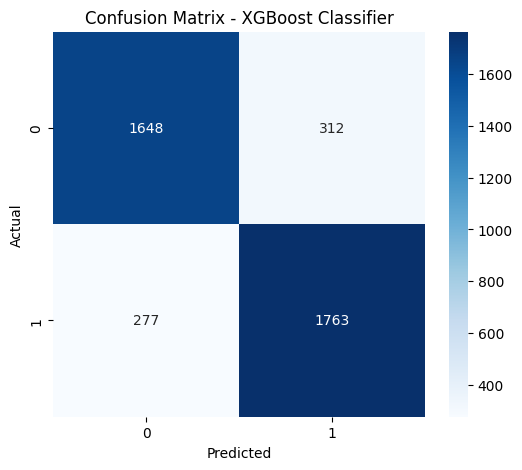

In [70]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6,5))
sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - XGBoost Classifier")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Model Performance Evaluation & Comparison

In [71]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree":decision_tree ,
    "Random Forest": random_forest,
    "KNN": knn_model ,
    "SVM": svm_model,
    "Naive Bayes": nb,
    "Gradient Boosting": gradient_boosting,
    "AdaBoost": adaboost,
    "XGBoost": xgb_classifier
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_test, y_pred) * 100,
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Accuracy (%)", ascending=False
).reset_index(drop=True)

print("9 Models Comparison")
display(comparison_df.round(4))


9 Models Comparison


,Model,Accuracy (%),Precision,Recall,F1 Score
0,Decision Tree,85.400,0.8540,0.8540,0.8540
1,AdaBoost,85.325,0.8534,0.8532,0.8533
2,Gradient Boosting,85.275,0.8528,0.8528,0.8527
3,XGBoost,85.275,0.8528,0.8528,0.8527
4,SVM,85.200,0.8520,0.8520,0.8520
5,Logistic Regression,85.125,0.8513,0.8512,0.8513
6,Random Forest,84.775,0.8478,0.8478,0.8477
7,Naive Bayes,84.725,0.8472,0.8472,0.8472
8,KNN,80.000,0.8000,0.8000,0.8000


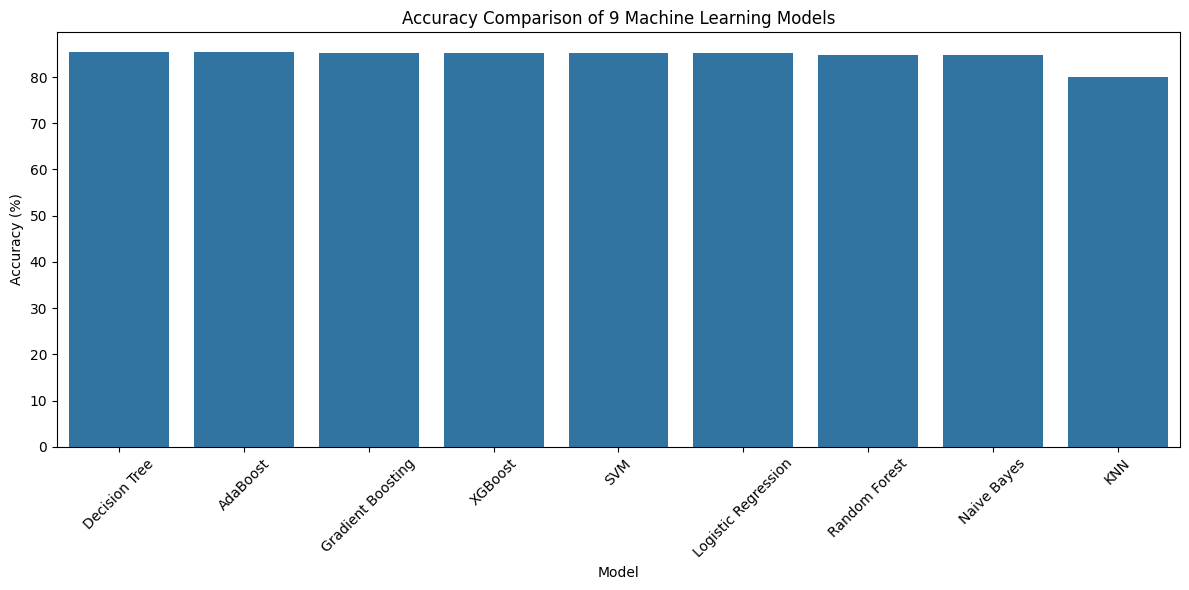

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Accuracy Comparison of 9 Machine Learning Models")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Best Performing Model — Before Tuning

In [73]:
best_model_name = comparison_df.loc[
    comparison_df["Accuracy (%)"].idxmax(), "Model"
]

print("Best Model:", best_model_name)

print(
    "Best Accuracy:",
    comparison_df["Accuracy (%)"].max(), "%"
)

Best Model: Decision Tree
Best Accuracy: 85.39999999999999 %


## Hyperparameter Tuning

### Logistic Regression

In [74]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Define parameters
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs"],
    "max_iter": [500, 1000]
}

# 2. Initialize Logistic Regression
lr_model = LogisticRegression(random_state=42)

# 3. Hyperparameter Tuning
lr_grid = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

lr_grid.fit(X_train_scaled, y_train)

# 4. Best Parameters
best_lr = lr_grid.best_estimator_

print("Best Parameters:", lr_grid.best_params_)
print("Best CV Accuracy:", lr_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_lr_tuned = best_lr.predict(X_test_scaled)

print("Tuned Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr_tuned) * 100, "%")

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_tuned))

# 7. Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_tuned))

Best Parameters: {'C': 0.1, 'max_iter': 500, 'solver': 'lbfgs'}
Best CV Accuracy: 86.63748622459133 %
Tuned Logistic Regression Accuracy: 85.075 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1960
           1       0.85      0.85      0.85      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000

Confusion Matrix:
[[1659  301]
 [ 296 1744]]


### Decision Tree Classifier

In [75]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Define parameters
param_grid_dt = {
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"]
}

# 2. Initialize Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

# 3. Hyperparameter Tuning
dt_grid = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid_dt,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

dt_grid.fit(X_train_scaled, y_train)

# 4. Best Parameters
best_dt = dt_grid.best_estimator_

print("Best Parameters:", dt_grid.best_params_)
print("Best CV Accuracy:", dt_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_dt_tuned = best_dt.predict(X_test_scaled)

print(
    "Tuned Decision Tree Accuracy:",
    accuracy_score(y_test, y_pred_dt_tuned) * 100, "%"
)

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_tuned))

# 7. Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt_tuned))

Best Parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best CV Accuracy: 86.38747177041647 %
Tuned Decision Tree Accuracy: 85.39999999999999 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1960
           1       0.85      0.86      0.86      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000


Confusion Matrix:
[[1660  300]
 [ 284 1756]]


### Random Forest Classifier

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV Accuracy: 86.6874870061831 %
Tuned Random Forest Accuracy: 85.175 %

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1960
           1       0.85      0.86      0.86      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



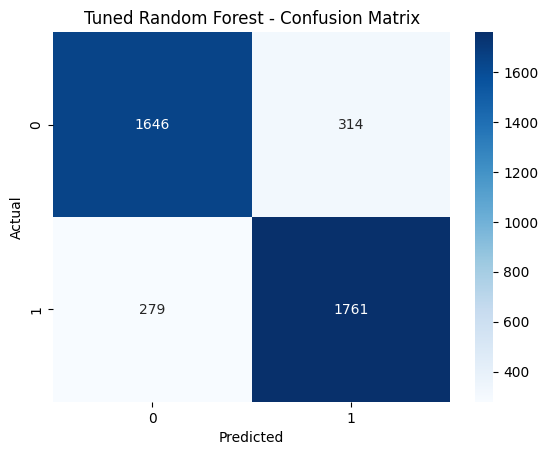

In [76]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define parameters
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# 2. Initialize Random Forest
rf_model = RandomForestClassifier(random_state=42)

# 3. Hyperparameter Tuning
rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

# 4. Best Model
best_rf = rf_grid.best_estimator_

print("Best Parameters:", rf_grid.best_params_)
print("Best CV Accuracy:", rf_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_rf_tuned = best_rf.predict(X_test_scaled)

print(
    "Tuned Random Forest Accuracy:",
    accuracy_score(y_test, y_pred_rf_tuned) * 100, "%"
)

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_tuned))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf_tuned)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Tuned Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### KNeighbors Classifier

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best CV Accuracy: 82.46872173980316 %
Tuned KNN Accuracy: 82.975 %

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83      1960
           1       0.83      0.83      0.83      2040

    accuracy                           0.83      4000
   macro avg       0.83      0.83      0.83      4000
weighted avg       0.83      0.83      0.83      4000



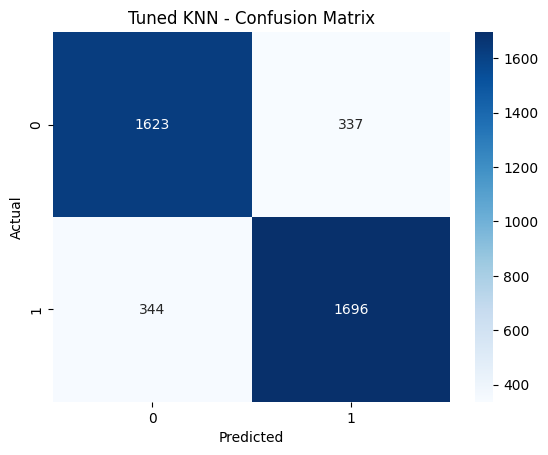

In [77]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define parameters
param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

# 2. Initialize KNN
knn_model = KNeighborsClassifier()

# 3. Hyperparameter Tuning
knn_grid = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid_knn,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(X_train_scaled, y_train)

# 4. Best Model
best_knn = knn_grid.best_estimator_

print("Best Parameters:", knn_grid.best_params_)
print("Best CV Accuracy:", knn_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_knn_tuned = best_knn.predict(X_test_scaled)

print(
    "Tuned KNN Accuracy:",
    accuracy_score(y_test, y_pred_knn_tuned) * 100, "%"
)

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn_tuned))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_knn_tuned)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Tuned KNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### SVC

Best Parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV Accuracy: 86.71873075681779 %
Tuned SVM Accuracy: 85.1 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1960
           1       0.85      0.86      0.85      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



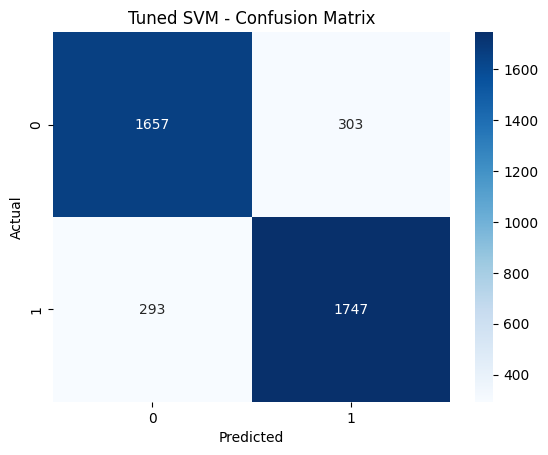

In [78]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define parameters
param_grid_svm = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}

# 2. Initialize SVM
svm_model = SVC()

# 3. Hyperparameter Tuning
svm_grid = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid_svm,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

# 4. Best Model
best_svm = svm_grid.best_estimator_

print("Best Parameters:", svm_grid.best_params_)
print("Best CV Accuracy:", svm_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_svm_tuned = best_svm.predict(X_test_scaled)

print(
    "Tuned SVM Accuracy:",
    accuracy_score(y_test, y_pred_svm_tuned) * 100, "%"
)

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm_tuned))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_svm_tuned)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Tuned SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### GaussianNB

Best Parameters: {'var_smoothing': 1e-09}
Best CV Accuracy: 85.5562354349434 %
Tuned Naive Bayes Accuracy: 84.725 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.84      0.84      1960
           1       0.85      0.85      0.85      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



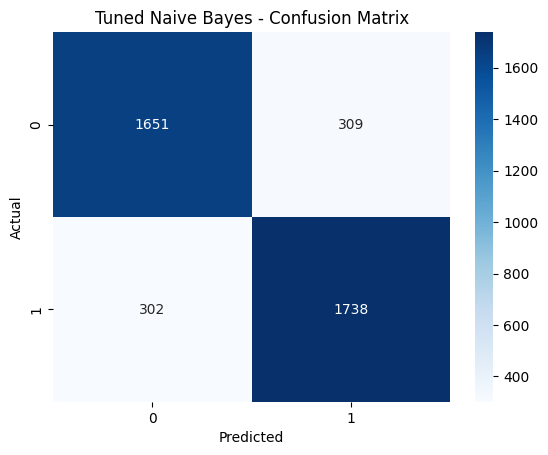

In [79]:
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define parameters
param_grid_nb = {
    "var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
}

# 2. Initialize Naive Bayes
nb_model = GaussianNB()

# 3. Hyperparameter Tuning
nb_grid = GridSearchCV(
    estimator=nb_model,
    param_grid=param_grid_nb,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

nb_grid.fit(X_train_scaled, y_train)

# 4. Best Model
best_nb = nb_grid.best_estimator_

print("Best Parameters:", nb_grid.best_params_)
print("Best CV Accuracy:", nb_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_nb_tuned = best_nb.predict(X_test_scaled)

print(
    "Tuned Naive Bayes Accuracy:",
    accuracy_score(y_test, y_pred_nb_tuned) * 100, "%"
)

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb_tuned))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_nb_tuned)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Tuned Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### GradientBoostingClassifier

Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best CV Accuracy: 86.72498700647606 %
Tuned Gradient Boosting Accuracy: 85.275 %

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1960
           1       0.85      0.86      0.86      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



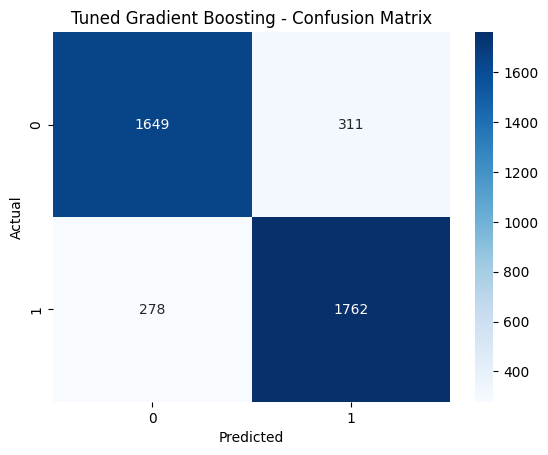

In [80]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define parameters
param_grid_gb = {
    "n_estimators": [100, 150],
    "learning_rate": [0.01, 0.1],
    "max_depth": [2, 3, 5]
}

# 2. Initialize Gradient Boosting
gb_model = GradientBoostingClassifier(random_state=42)

# 3. Hyperparameter Tuning
gb_grid = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid_gb,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

gb_grid.fit(X_train_scaled, y_train)

# 4. Best Model
best_gb = gb_grid.best_estimator_

print("Best Parameters:", gb_grid.best_params_)
print("Best CV Accuracy:", gb_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_gb_tuned = best_gb.predict(X_test_scaled)

print(
    "Tuned Gradient Boosting Accuracy:",
    accuracy_score(y_test, y_pred_gb_tuned) * 100, "%"
)

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb_tuned))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_gb_tuned)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Tuned Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### AdaBoostClassifier

Best Parameters: {'learning_rate': 0.1, 'n_estimators': 150}
Best CV Accuracy: 86.38123544138833 %
Tuned AdaBoost Accuracy: 85.3 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1960
           1       0.86      0.85      0.85      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



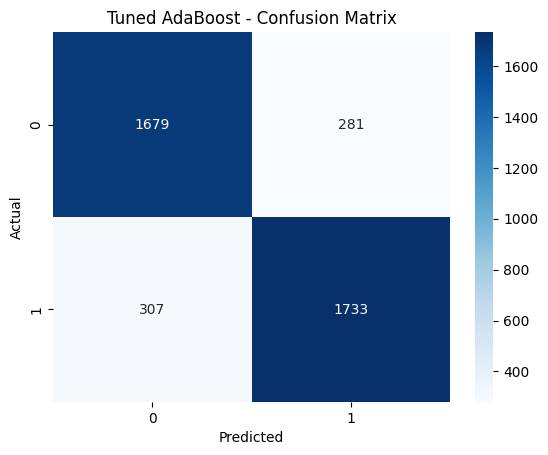

In [81]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define parameters
param_grid_ada = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.01, 0.1, 1.0]
}

# 2. Initialize AdaBoost
ada_model = AdaBoostClassifier(random_state=42)

# 3. Hyperparameter Tuning
ada_grid = GridSearchCV(
    estimator=ada_model,
    param_grid=param_grid_ada,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

ada_grid.fit(X_train_scaled, y_train)

# 4. Best Model
best_ada = ada_grid.best_estimator_

print("Best Parameters:", ada_grid.best_params_)
print("Best CV Accuracy:", ada_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_ada_tuned = best_ada.predict(X_test_scaled)

print(
    "Tuned AdaBoost Accuracy:",
    accuracy_score(y_test, y_pred_ada_tuned) * 100, "%"
)

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ada_tuned))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_ada_tuned)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Tuned AdaBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### XGBClassifier

Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}
Best CV Accuracy: 86.65624325554843 %
Tuned XGBoost Accuracy: 85.25 %

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1960
           1       0.85      0.87      0.86      2040

    accuracy                           0.85      4000
   macro avg       0.85      0.85      0.85      4000
weighted avg       0.85      0.85      0.85      4000



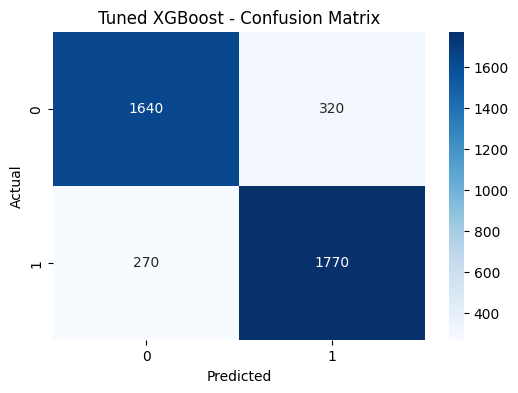

In [82]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define parameters
param_grid_xgb = {
    "n_estimators": [100, 150],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1]
}

# 2. Initialize XGBoost
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

# 3. Hyperparameter Tuning
xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid_xgb,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

xgb_grid.fit(X_train_scaled, y_train)

# 4. Best Model
best_xgb = xgb_grid.best_estimator_

print("Best Parameters:", xgb_grid.best_params_)
print("Best CV Accuracy:", xgb_grid.best_score_ * 100, "%")

# 5. Test Accuracy
y_pred_xgb_tuned = best_xgb.predict(X_test_scaled)

print(
    "Tuned XGBoost Accuracy:",
    accuracy_score(y_test, y_pred_xgb_tuned) * 100, "%"
)

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_tuned))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb_tuned)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Tuned XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [83]:
from sklearn.metrics import accuracy_score
import pandas as pd

tuned_models = {
    "Logistic Regression": best_lr,
    "Decision Tree": best_dt,
    "Random Forest": best_rf,
    "KNN": best_knn,
    "SVM": best_svm,
    "Naive Bayes": best_nb,
    "Gradient Boosting": best_gb,
    "AdaBoost": best_ada,
    "XGBoost": best_xgb
}

results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Tuned Accuracy (%)": round(
            accuracy_score(y_test, y_pred) * 100, 2
        )
    })

tuned_comparison_df = pd.DataFrame(results)
tuned_comparison_df = tuned_comparison_df.sort_values(
    by="Tuned Accuracy (%)", ascending=False
).reset_index(drop=True)

display(tuned_comparison_df)

print("\nBest Tuned Model:", tuned_comparison_df.iloc[0]["Model"])
print("Best Accuracy:", tuned_comparison_df.iloc[0]["Tuned Accuracy (%)"], "%")

,Model,Tuned Accuracy (%)
0,Decision Tree,85.40
1,AdaBoost,85.30
2,Gradient Boosting,85.28
3,XGBoost,85.25
4,Random Forest,85.17
5,SVM,85.10
6,Logistic Regression,85.08
7,Naive Bayes,84.72
8,KNN,82.97



Best Tuned Model: Decision Tree
Best Accuracy: 85.4 %


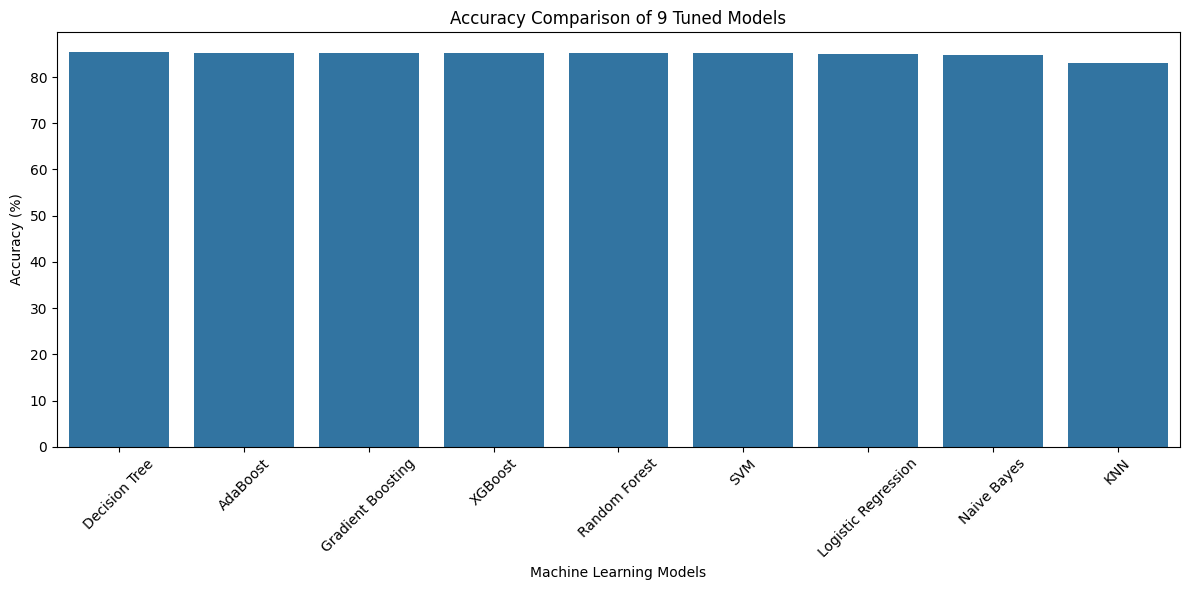

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=tuned_comparison_df,
    x="Model",
    y="Tuned Accuracy (%)"
)

plt.title("Accuracy Comparison of 9 Tuned Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Final Model Comparison — Before vs After Tuning

In [86]:
final_comparison_df = pd.merge(
    comparison_df[["Model", "Accuracy (%)"]],
    tuned_comparison_df[["Model", "Tuned Accuracy (%)"]],
    on="Model",
    how="inner"
)

final_comparison_df = final_comparison_df.rename(
    columns={"Accuracy (%)": "Original Accuracy (%)"}
)

display(final_comparison_df)

,Model,Original Accuracy (%),Tuned Accuracy (%)
0,Decision Tree,85.400,85.40
1,AdaBoost,85.325,85.30
2,Gradient Boosting,85.275,85.28
3,XGBoost,85.275,85.25
4,SVM,85.200,85.10
5,Logistic Regression,85.125,85.08
6,Random Forest,84.775,85.17
7,Naive Bayes,84.725,84.72
8,KNN,80.000,82.97


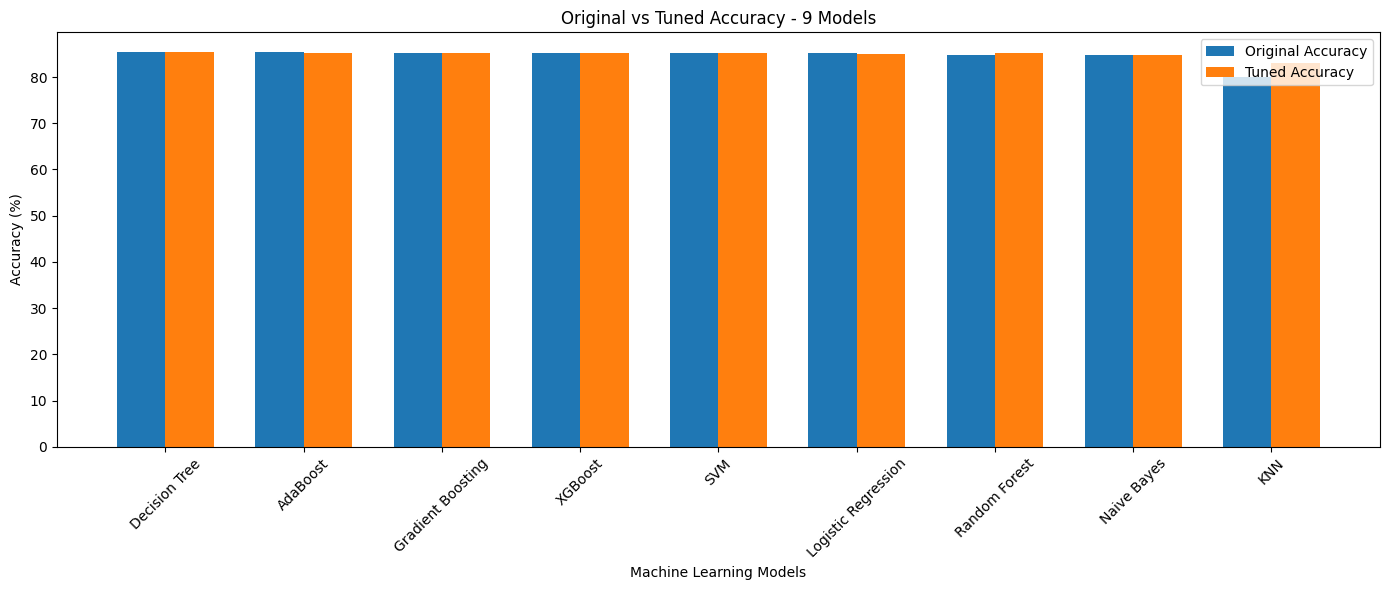

In [87]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(final_comparison_df))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(
    x - width/2,
    final_comparison_df["Original Accuracy (%)"],
    width,
    label="Original Accuracy"
)

plt.bar(
    x + width/2,
    final_comparison_df["Tuned Accuracy (%)"],
    width,
    label="Tuned Accuracy"
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.title("Original vs Tuned Accuracy - 9 Models")
plt.xticks(x, final_comparison_df["Model"], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [88]:
import joblib

joblib.dump(best_dt, "ad_engagement_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(X_encoded.columns.tolist(), "model_columns.pkl")

print("Model, scaler, and columns saved successfully!")

Model, scaler, and columns saved successfully!


#

#

## Conclusion

##### Developed a Machine Learning model to predict whether users are likely to click on advertisements.

##### Evaluated nine Machine Learning algorithms and compared their performance.

##### Achieved the highest reported accuracy of 85.40% using the Decision Tree model.

##### Demonstrated how ad engagement prediction can support data-driven marketing decisions.